In [1]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
df = pd.read_csv("dataset.csv")

In [12]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types and missing values:")
df.info()

Dataset shape: (6347, 19)

Column names:
['Unnamed: 0', 'Price', 'Area', 'Location', 'No. of Bedrooms', 'New/Resale', 'Gymnasium', 'Lift Available', 'Car Parking', 'Maintenance Staff', '24x7 Security', 'Children', 'Clubhouse', 'Intercom', 'Landscaped Gardens', 'Indoor Games', 'Gas Connection', 'Jogging Track', 'Swimming Pool']

First 5 rows:
   Unnamed: 0    Price  Area  Location  No. of Bedrooms  New/Resale  \
0           0  4850000   720  Kharghar                1           0   
1           1  4500000   600  Kharghar                1           0   
2           2  6700000   650  Kharghar                1           0   
3           3  4500000   650  Kharghar                1           0   
4           4  5000000   665  Kharghar                1           0   

   Gymnasium  Lift Available  Car Parking  Maintenance Staff  24x7 Security  \
0          0               1            1                  1              1   
1          1               1            1                  1           

In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

amenity_columns = [
    "Gymnasium",
    "Lift Available",
    "Car Parking",
    "Maintenance Staff",
    "24x7 Security",
    "Children",
    "Clubhouse",
    "Intercom",
    "Landscaped Gardens",
    "Indoor Games",
    "Gas Connection",
    "Jogging Track",
    "Swimming Pool"
]

numeric_features = [
    "Area",
    "No. of Bedrooms",
    "New/Resale"
] + amenity_columns

categorical_features = ["Location"]
feature_columns = numeric_features + categorical_features

data = df[feature_columns + ["Price"]].copy()

data["Price"] = pd.to_numeric(data["Price"], errors="coerce")

for col in numeric_features:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["Price", "Location"])
data = data[data["Price"] > 0]

data["Location"] = data["Location"].astype(str).str.strip()
data = data[data["Location"] != ""]

X = data[feature_columns]
y = data["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model evaluation")
print("----------------")
print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"MAE: ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

print(f"\nMAE in lakhs: ₹{mae / 100000:.2f} lakhs")
print(f"RMSE in lakhs: ₹{rmse / 100000:.2f} lakhs")


Model evaluation
----------------
Training records: 5077
Testing records: 1270
MAE: ₹5,356,144.65
RMSE: ₹11,102,533.35
R² Score: 0.6065

MAE in lakhs: ₹53.56 lakhs
RMSE in lakhs: ₹111.03 lakhs


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


                                   Feature  Coefficient  Absolute Coefficient
  categorical__Location_Worli South Mumbai 1.347015e+08          1.347015e+08
           categorical__Location_juhu tara 1.289052e+08          1.289052e+08
       categorical__Location_Hanuman Nagar 1.031084e+08          1.031084e+08
        categorical__Location_Breach Candy 9.654022e+07          9.654022e+07
      categorical__Location_worli sea Fase 8.136067e+07          8.136067e+07
         categorical__Location_Lower Parel 7.065080e+07          7.065080e+07
           categorical__Location_Yari Road 6.703040e+07          6.703040e+07
              categorical__Location_Tardeo 6.543667e+07          6.543667e+07
      categorical__Location_Napeansea Road 5.876421e+07          5.876421e+07
         categorical__Location_Peddar Road 5.779756e+07          5.779756e+07
categorical__Location_Bandra Kurla Complex 5.148652e+07          5.148652e+07
               categorical__Location_Worli 5.009214e+07         

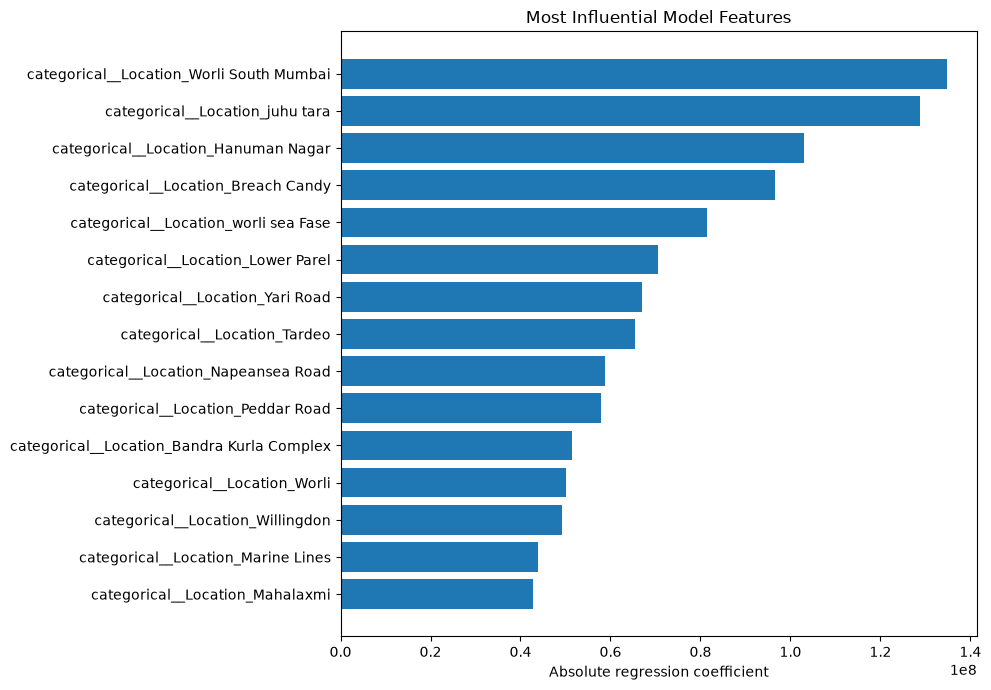

In [ ]:

regressor = model.named_steps["regressor"]
preprocessor = model.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": regressor.coef_
})

importance_df["Absolute Coefficient"] = (
    importance_df["Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(importance_df.head(20).to_string(index=False))

import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    "Absolute Coefficient"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Absolute Coefficient"]
)
plt.xlabel("Absolute regression coefficient")
plt.title("Most Influential Model Features")
plt.tight_layout()
plt.show()


In [15]:

new_property = pd.DataFrame([{
    "Area": 1000,
    "No. of Bedrooms": 2,
    "New/Resale": 0,
    "Gymnasium": 1,
    "Lift Available": 1,
    "Car Parking": 1,
    "Maintenance Staff": 1,
    "24x7 Security": 1,
    "Children": 1,
    "Clubhouse": 1,
    "Intercom": 1,
    "Landscaped Gardens": 1,
    "Indoor Games": 0,
    "Gas Connection": 1,
    "Jogging Track": 1,
    "Swimming Pool": 0,
    "Location": "Kharghar"
}])

predicted_price = model.predict(new_property)[0]

print(f"Predicted price: ₹{predicted_price:,.0f}")
print(f"Predicted price in lakhs: ₹{predicted_price / 100000:.2f} lakhs")


Predicted price: ₹4,948,413
Predicted price in lakhs: ₹49.48 lakhs


In [17]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": model,

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", ExtraTreesRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, candidate in models.items():
    if name != "Linear Regression":
        candidate.fit(X_train, y_train)

    predictions = candidate.predict(X_test)

    results.append({
        "Model": name,
        "MAE (lakhs)": mean_absolute_error(
            y_test, predictions
        ) / 100000,
        "RMSE (lakhs)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ) / 100000,
        "R² Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "R² Score", ascending=False
)

print(results_df.round(4).to_string(index=False))


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


            Model  MAE (lakhs)  RMSE (lakhs)  R² Score
Linear Regression      53.5614      111.0253    0.6065
      Extra Trees      42.2297      125.4710    0.4974
    Random Forest      45.0581      132.3958    0.4404


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [18]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Compare the fitted models on the same test properties
diagnostics = []

for name in ["Linear Regression", "Extra Trees", "Random Forest"]:
    fitted_model = models[name]
    predictions = fitted_model.predict(X_test)
    errors = np.abs(y_test.to_numpy() - predictions)

    diagnostics.append({
        "Model": name,
        "MAE (lakhs)": errors.mean() / 100000,
        "Median error (lakhs)": np.median(errors) / 100000,
        "Errors > 100 lakh": (errors > 10000000).sum(),
        "Errors > 200 lakh": (errors > 20000000).sum(),
        "R²": r2_score(y_test, predictions)
    })

print("PRICE DISTRIBUTION (lakhs)")
print((y_train.describe() / 100000).round(2))

print("\nERROR DIAGNOSTICS")
print(pd.DataFrame(diagnostics).round(3).to_string(index=False))


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


PRICE DISTRIBUTION (lakhs)
count       0.05
mean      152.82
std       207.28
min        20.00
25%        53.00
50%        95.00
75%       175.00
max      4200.00
Name: Price, dtype: float64

ERROR DIAGNOSTICS
            Model  MAE (lakhs)  Median error (lakhs)  Errors > 100 lakh  Errors > 200 lakh    R²
Linear Regression       53.561                31.854                124                 48 0.606
      Extra Trees       42.230                13.151                105                 50 0.497
    Random Forest       45.058                14.953                117                 53 0.440


In [22]:

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

log_models = {
    "Log Linear Regression": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", LinearRegression())
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    ),
    "Log Extra Trees": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", ExtraTreesRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    )
}

log_results = []

for name, candidate in log_models.items():
    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)

    log_results.append({
        "Model": name,
        "MAE (lakhs)": mean_absolute_error(
            y_test, predictions
        ) / 100000,
        "RMSE (lakhs)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ) / 100000,
        "R² Score": r2_score(y_test, predictions)
    })

print(pd.DataFrame(log_results).round(4).to_string(index=False))


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


                Model  MAE (lakhs)  RMSE (lakhs)  R² Score
Log Linear Regression      36.1147      107.4132    0.6317
      Log Extra Trees      40.5272      120.8759    0.5335


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [21]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

comparison = []

for name, candidate in [
    ("Original Linear Regression", model),
    ("Log Linear Regression", log_models["Log Linear Regression"])
]:
    predictions = candidate.predict(X_test)

    comparison.append({
        "Model": name,
        "MAE (lakhs)": mean_absolute_error(
            y_test, predictions
        ) / 100000,
        "RMSE (lakhs)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ) / 100000,
        "R²": r2_score(y_test, predictions)
    })

print(pd.DataFrame(comparison).round(4).to_string(index=False))


                     Model  MAE (lakhs)  RMSE (lakhs)     R²
Original Linear Regression      53.5614      111.0253 0.6065
     Log Linear Regression      36.1147      107.4132 0.6317


c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\BISWAS\Desktop\C_work\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [23]:
import pandas as pd
import numpy as np

test_property = pd.DataFrame([{
    "Area": 1050,
    "No. of Bedrooms": 2,
    "New/Resale": 0,
    "Gymnasium": 1,
    "Lift Available": 1,
    "Car Parking": 1,
    "Maintenance Staff": 1,
    "24x7 Security": 1,
    "Children": 1,
    "Clubhouse": 1,
    "Intercom": 0,
    "Landscaped Gardens": 1,
    "Indoor Games": 0,
    "Gas Connection": 1,
    "Jogging Track": 1,
    "Swimming Pool": 0,
    "Location": "Kharghar"
}])

# Predict using our trained Log Linear Regression model
predicted_price = log_models["Log Linear Regression"].predict(
    test_property
)[0]

print(f"Predicted price: ₹{predicted_price:,.0f}")
print(f"Predicted price: ₹{predicted_price / 100000:.2f} lakh")

Predicted price: ₹7,864,903
Predicted price: ₹78.65 lakh


In [24]:

import joblib
import json

# Save the winning trained model
best_model = log_models["Log Linear Regression"]
joblib.dump(best_model, "house_price_model.joblib")

# Get localities actually seen during model training
fitted_pipeline = best_model.regressor_
encoder = (
    fitted_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["categorical"]
    .named_steps["encoder"]
)

known_locations = sorted(str(x) for x in encoder.categories_[0])

with open("locations.json", "w", encoding="utf-8") as f:
    json.dump(known_locations, f, ensure_ascii=False, indent=2)

print("Model and locality list saved successfully!")
print("Known localities:", len(known_locations))


Model and locality list saved successfully!
Known localities: 376
